# DS-A2 — Statistical Inference and Uncertainty

**Day–Night Variability in Underwater Sound Levels: Statistical Inference, Power, and Temporal Dependence**

This notebook analyzes the NOAA SanctSound SB02_13 hourly broadband sound-level indicator. It separates observed data from controlled simulations and makes no causal claims about nighttime, vessels, marine animals, or other potential sound sources.

Run all cells sequentially from a clean Jupyter kernel using a Python environment with the dependencies documented in the repository. The frozen experimental design is specified in `config/experiment_protocol.yaml`, with statistical methods implemented in `src/inference.py` and experiment orchestration in `src/run_phase1.py`.

## 1. Research question and estimand

For eligible dates in this deployment, is the average nighttime underwater sound indicator different from the daytime indicator, and how uncertain is that difference? The sampling unit is a local calendar date.

For each date, `D_d = mean(night published hourly dB) − mean(day published hourly dB)`. The estimand is the expected `D_d` under the eligible observation process at this one station and deployment; the estimator is the mean of observed eligible differences. These arithmetic means of dB indicators are **not** means of linear acoustic energy. Generalization beyond this deployment needs additional assumptions.

The hypotheses are `H0: Delta = 0` versus two-sided `H1: Delta != 0`, alpha 0.05, with 95% intervals. The 3 dB primary and 1 dB secondary values are pre-specified operational interpretation thresholds, not universal acoustic/ecological standards and not null hypotheses. Statistical significance and practical importance are distinct.


## 2. Data provenance and measurement

The source is NOAA SanctSound SB02_13_BB_1h, DOI [10.25921/yyt5-g930](https://doi.org/10.25921/yyt5-g930), retrieved from the official NOAA public bucket. The original CSV checksum and provenance are recorded in `results/audit/provenance.json`; the protocol also pins its SHA-256. Direct netCDF attributes identify UTC labels as the start of each one-hour bin. `America/New_York` is used for local-clock windows. The data span November 2020 to January 2021 and do not contain a daylight-saving transition.

The primary band label is 10–24,000 Hz based on netCDF/NCEI/field-name evidence; the exact product's brief JSON says 20–24,000 Hz, which remains unresolved. The file has no row-level QC flag, so no undocumented filtering is applied. The exact product's netCDF license permits free redistribution with disclaimers; no raw audio is included.


## 3. Frozen analysis and execution

Day is local `[09:00, 17:00)` and night is `[21:00, 05:00)` on the next local date, assigned to the night start date. Include at least six valid hours in each eight-hour window; 8/8 is a coverage sensitivity. Missing values are not interpolated.

The IID baseline is a one-sample t procedure. HAC uses an intercept-only Newey–West estimate with Bartlett weights, `floor(4*(n/100)^(2/9))` lags, `n/(n−1)` correction and a t reference with `n−1` degrees of freedom. MBB samples overlapping non-circular blocks, concatenates then truncates to n, and uses bootstrap-mean percentile intervals. Its primary block length is `ceil(n^(1/3))`, with lengths 2, 4, 8 as sensitivity. The confidence-interval decision is used for MBB; no bootstrap p-value is manufactured.

The following run cell validates the pinned source hash, checks paired-date eligibility against the Phase 0.5 audit, and computes the frozen observed-data and simulation analyses. All pseudo-random draws use explicit `numpy.random.default_rng` seeds from root 20261012.


In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from run_phase1 import run_all
results = run_all()
print("Pipeline completed with pinned source data and frozen protocol.")


AR(1) comparison rho=0.0, effect=0.0
AR(1) comparison rho=0.0, effect=3.0
AR(1) comparison rho=0.3, effect=0.0
AR(1) comparison rho=0.3, effect=3.0
AR(1) comparison rho=0.6, effect=0.0
AR(1) comparison rho=0.6, effect=3.0
AR(1) comparison rho=0.9, effect=0.0
AR(1) comparison rho=0.9, effect=3.0
Pipeline completed with pinned source data and frozen protocol.


## 4. Data preparation and eligibility

In [2]:
import pandas as pd
daily = pd.read_csv(ROOT / "data/processed/daily_analysis.csv")
eligible = daily.loc[daily.eligible_6_of_8].copy()
eligible_summary = {
    "all_dates_screened": len(daily),
    "eligible_6_of_8": int(daily.eligible_6_of_8.sum()),
    "eligible_8_of_8": int(daily.eligible_8_of_8.sum()),
    "first_eligible_date": eligible.local_date.iloc[0],
    "last_eligible_date": eligible.local_date.iloc[-1],
}
pd.Series(eligible_summary, name="value").to_frame()


,value
all_dates_screened,66
eligible_6_of_8,64
eligible_8_of_8,64
first_eligible_date,2020-11-23
last_eligible_date,2021-01-25


## 5. Observed-data inference

The three families target the same mean paired difference but encode different dependence assumptions. HAC intervals at n=64 are approximate, not guaranteed calibrated; MBB sensitivity to block size is shown explicitly. A 95% confidence interval describes the procedure's long-run coverage under its assumptions; it does not assign 95% probability to a fixed Delta. An interval containing zero does not establish that Delta equals zero.

In [3]:
from IPython.display import display
display(pd.DataFrame([results["descriptive"]]).T.rename(columns={0: "observed value"}))
display(pd.DataFrame(results["methods"])[["method", "mean", "lower", "upper", "p_value"]])


,observed value
eligible_primary_dates,64
eligible_strict_dates,64
eligible_date_range,"[2020-11-23, 2021-01-25]"
contiguous_runs,[64]
mean_difference_db,0.352137
median_difference_db,0.634544
sample_sd_ddof1_db,3.123155
standard_error_db,0.390394
minimum_difference_db,-7.765208
maximum_difference_db,7.008545


,method,mean,lower,upper,p_value
0,IID one-sample t,0.352137,-0.428004,1.132278,0.370490
1,Newey-West HAC,0.352137,-0.563540,1.267814,0.445066
2,Moving block bootstrap L=2,0.352137,-0.499504,1.136729,NaN
3,Moving block bootstrap L=4,0.352137,-0.541927,1.227979,NaN
4,Moving block bootstrap L=8,0.352137,-0.431345,1.245774,NaN


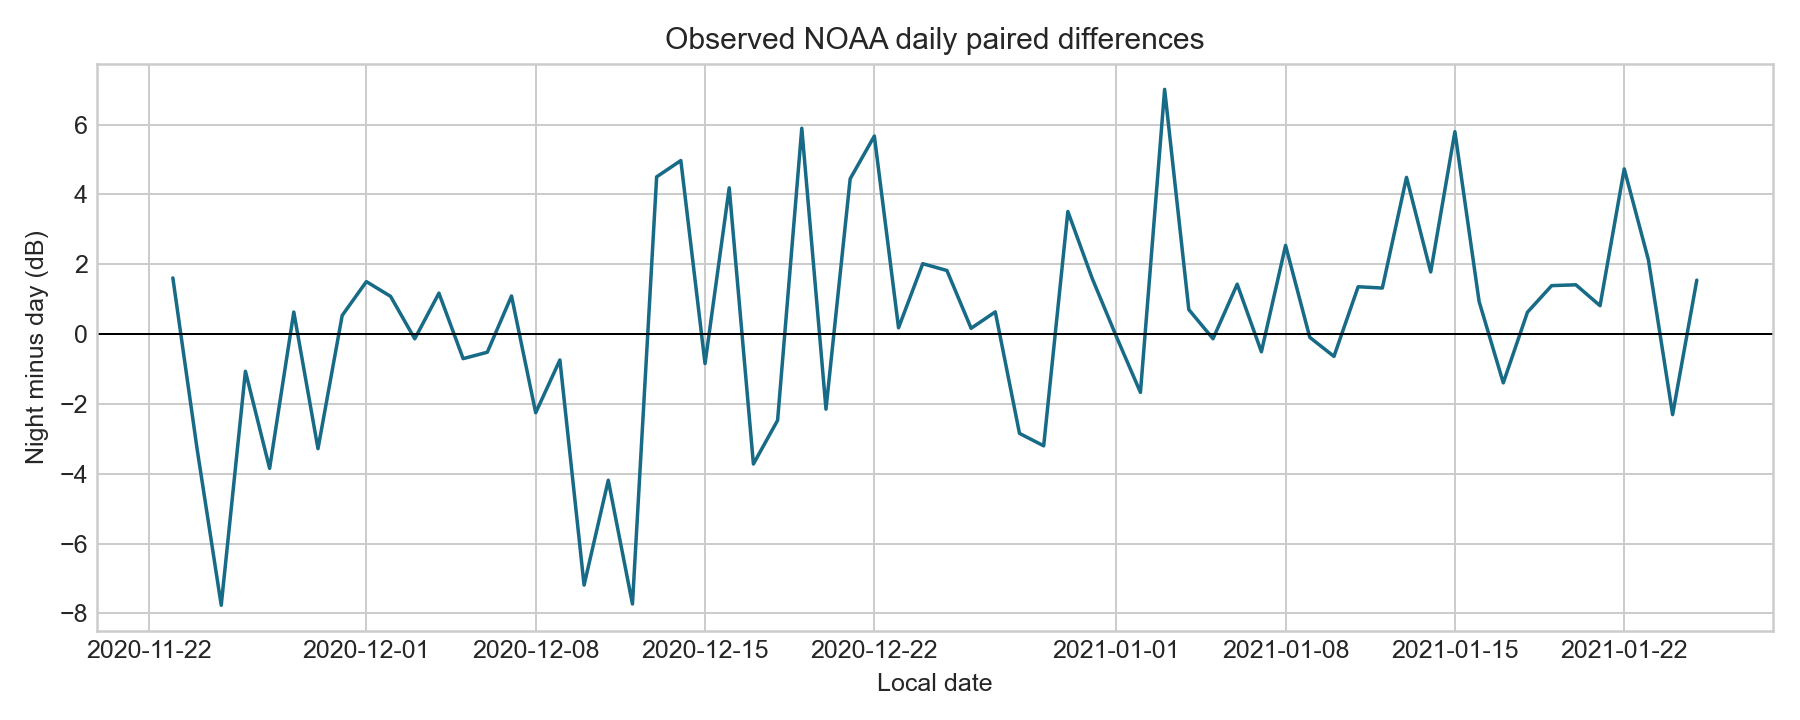

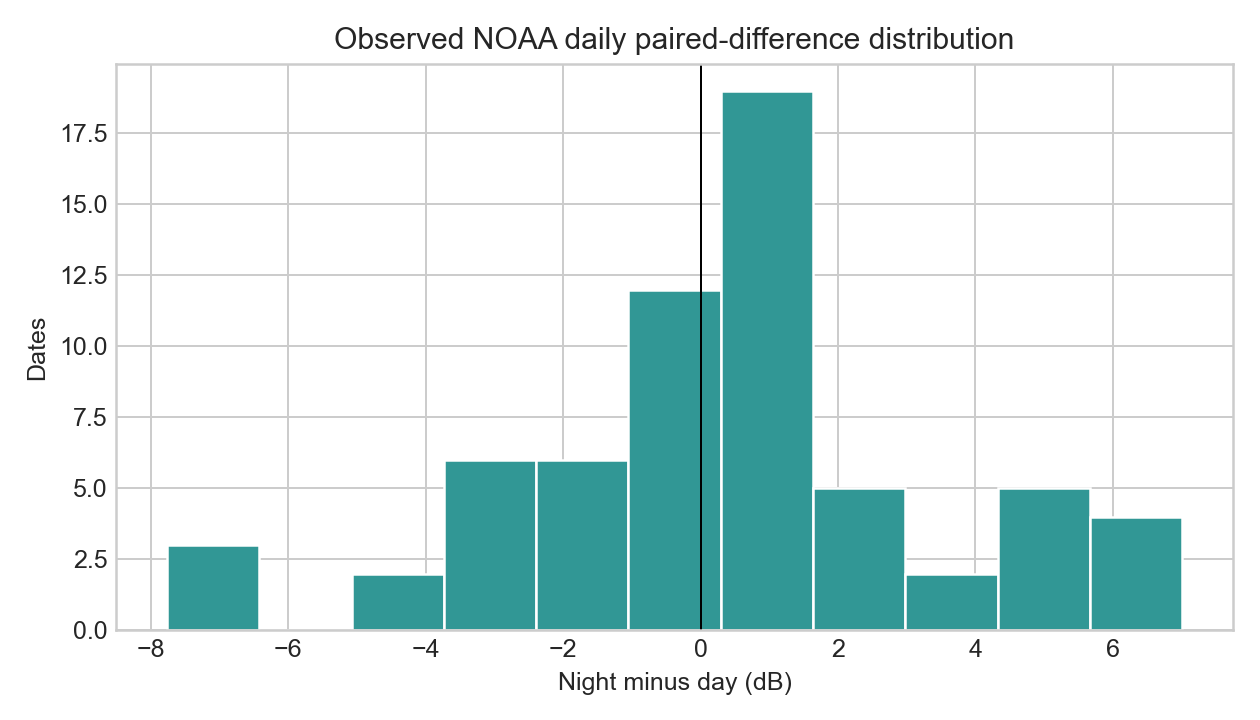

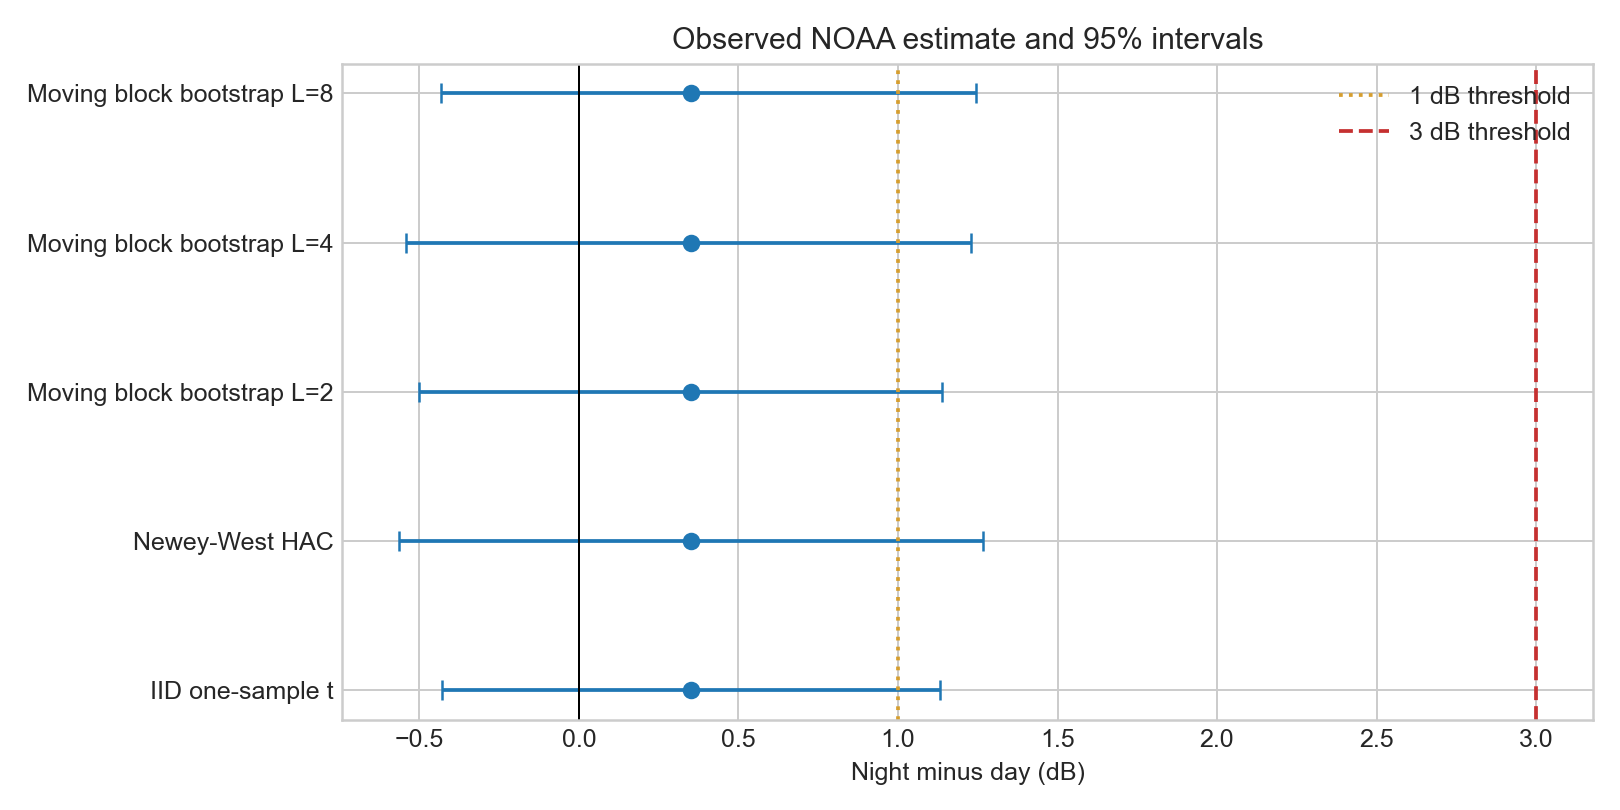

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "results/figures/daily_difference_timeseries.png")))
display(Image(filename=str(ROOT / "results/figures/daily_difference_distribution.png")))
display(Image(filename=str(ROOT / "results/figures/inference_intervals.png")))


## 6. Sampling-distribution simulation

A controlled IID Gaussian model uses the observed daily-difference sample SD as a marginal scale calibration. This calibration does not assert that NOAA daily differences are IID Gaussian. For each n/effect condition, Monte Carlo means are compared with the theoretical mean and standard error.

In [5]:
sampling = pd.read_csv(ROOT / "results/raw/sampling_distribution_summary.csv")
sampling[["n", "effect_db", "sigma_db", "theoretical_mean", "empirical_mean",
          "theoretical_se", "empirical_se", "estimated_bias"]]


,n,effect_db,sigma_db,theoretical_mean,empirical_mean,theoretical_se,empirical_se,estimated_bias
0,20,0.0,3.123155,0.0,-0.013773,0.698359,0.695620,-0.013773
1,20,3.0,3.123155,3.0,2.998591,0.698359,0.701566,-0.001409
2,30,0.0,3.123155,0.0,-0.008529,0.570207,0.577473,-0.008529
3,30,3.0,3.123155,3.0,3.000608,0.570207,0.577279,0.000608
4,64,0.0,3.123155,0.0,0.000330,0.390394,0.388829,0.000330
5,64,3.0,3.123155,3.0,2.991884,0.390394,0.387959,-0.008116


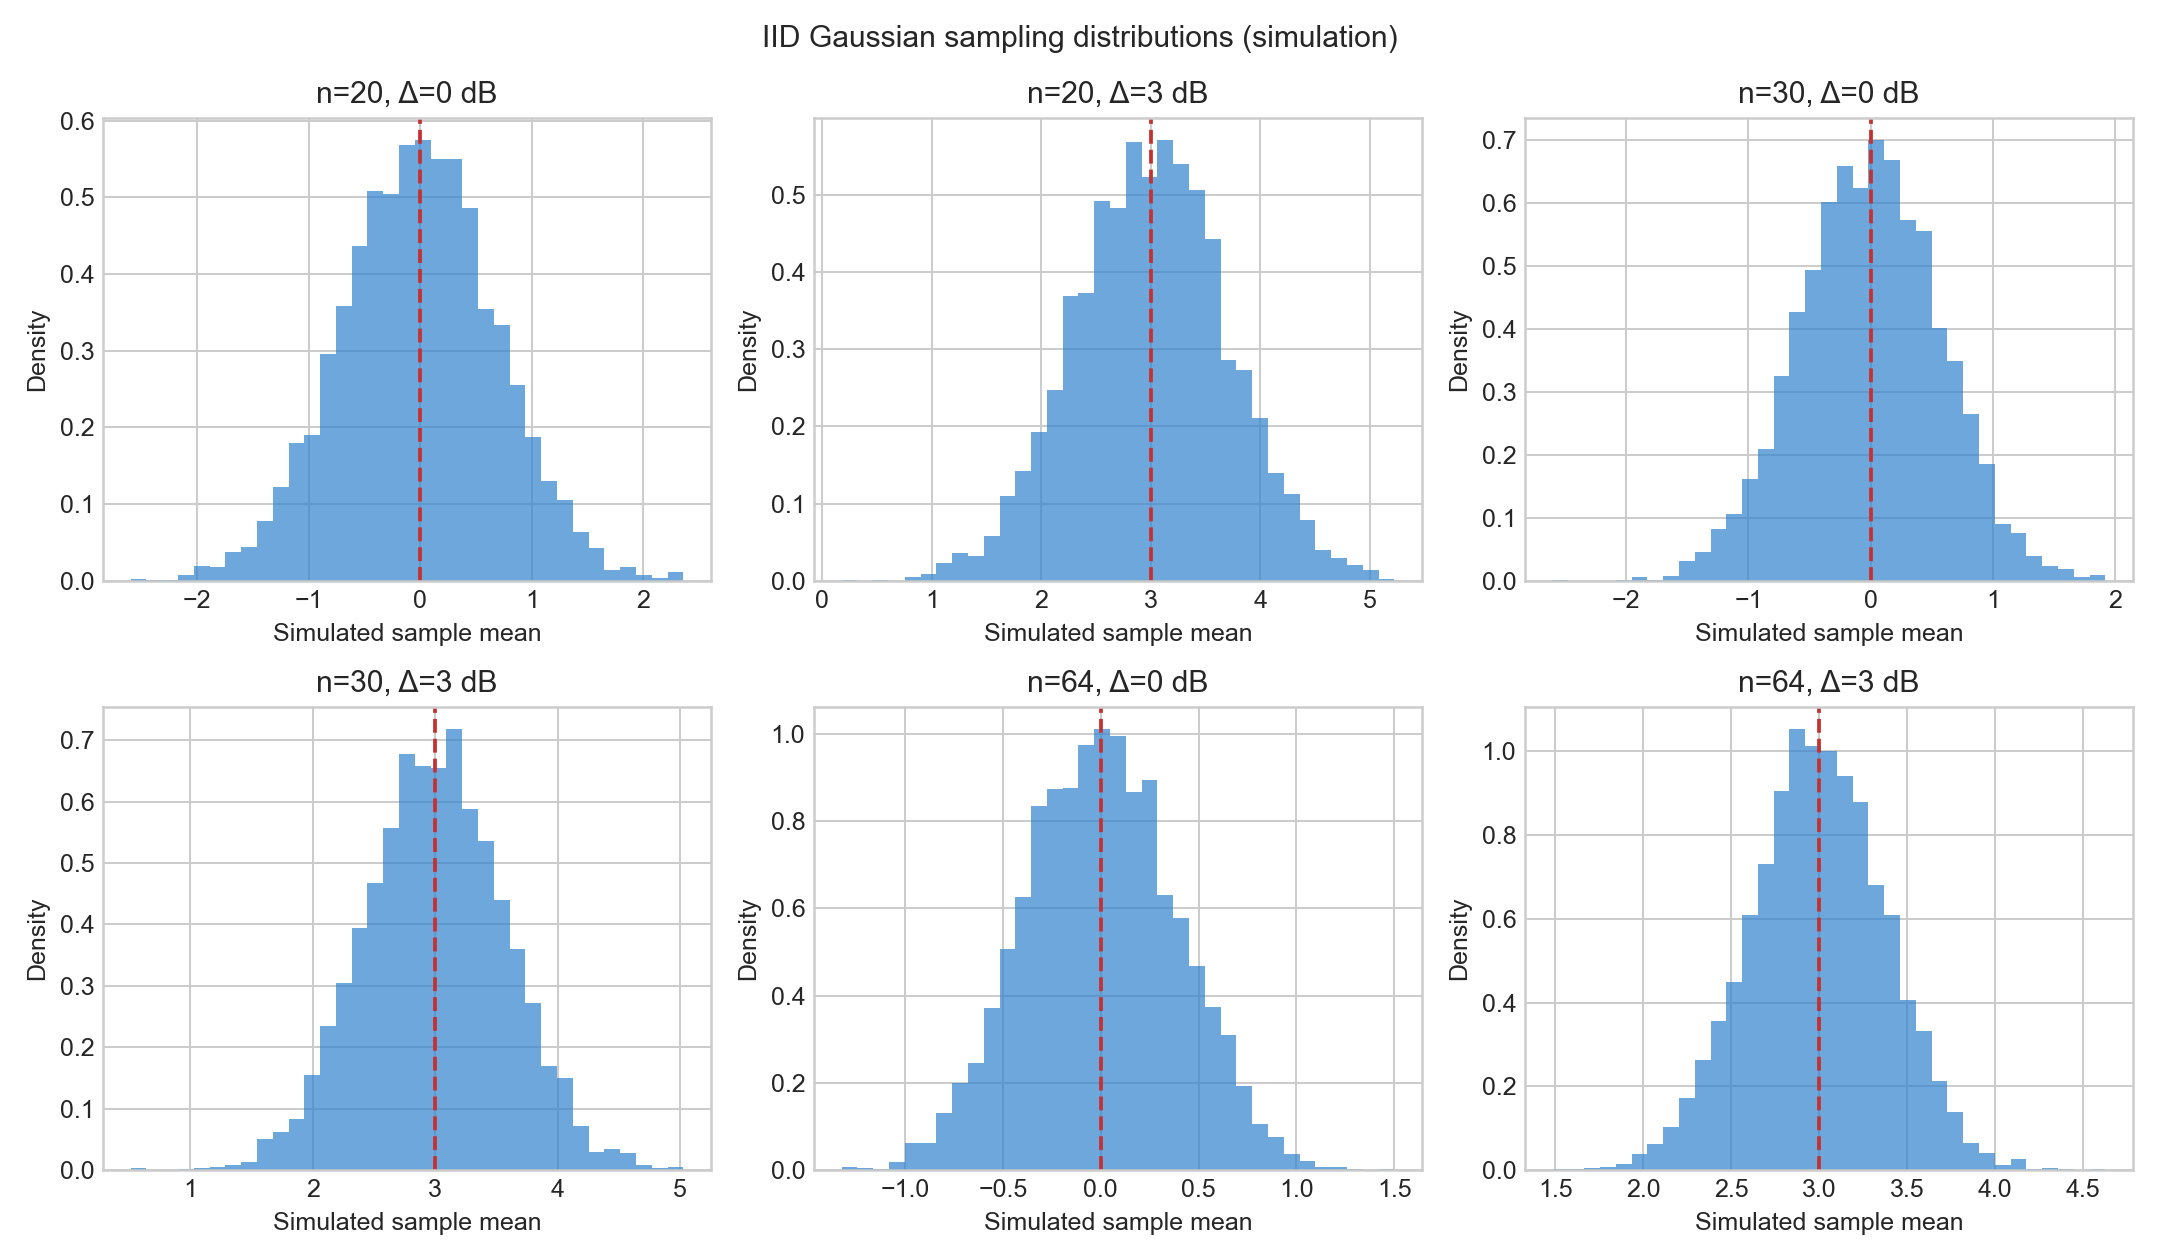

In [6]:
display(Image(filename=str(ROOT / "results/figures/sampling_distributions.png")))


## 7. Statistical power

The same two-sided t-test is used for every IID Monte Carlo scenario and for noncentral-t analytical power. At zero effect, the rejection rate estimates Type I error. Error bars show Wilson Monte Carlo intervals; analytical values apply only to the matching IID Gaussian model.

In [7]:
power = pd.read_csv(ROOT / "results/raw/iid_power.csv")
display(power)


,factor,x,n,sigma_db,effect_db,analytical_power,monte_carlo_rejection_rate,mc_ci_low,mc_ci_high,replications,seed,interpretation
0,sample_size,10.0,10,3.123155,3.0,0.771287,0.7734,0.761589,0.784791,5000,20261112,rejection rate
1,sample_size,20.0,20,3.123155,3.0,0.982572,0.9832,0.979249,0.986409,5000,20261113,rejection rate
2,sample_size,30.0,30,3.123155,3.0,0.999097,0.9990,0.997661,0.999573,5000,20261114,rejection rate
3,sample_size,40.0,40,3.123155,3.0,0.999963,1.0000,0.999232,1.000000,5000,20261115,rejection rate
4,sample_size,60.0,60,3.123155,3.0,1.000000,1.0000,0.999232,1.000000,5000,20261116,rejection rate
5,noise,0.5,30,1.561577,3.0,1.000000,1.0000,0.999232,1.000000,5000,20261117,rejection rate
6,noise,1.0,30,3.123155,3.0,0.999097,0.9996,0.998543,0.999890,5000,20261118,rejection rate
7,noise,1.5,30,4.684732,3.0,0.923526,0.9254,0.917786,0.932361,5000,20261119,rejection rate
8,noise,2.0,30,6.246310,3.0,0.719968,0.7134,0.700707,0.725766,5000,20261120,rejection rate
9,effect,0.0,30,3.123155,0.0,0.050000,0.0514,0.045617,0.057872,5000,20261121,empirical Type I error


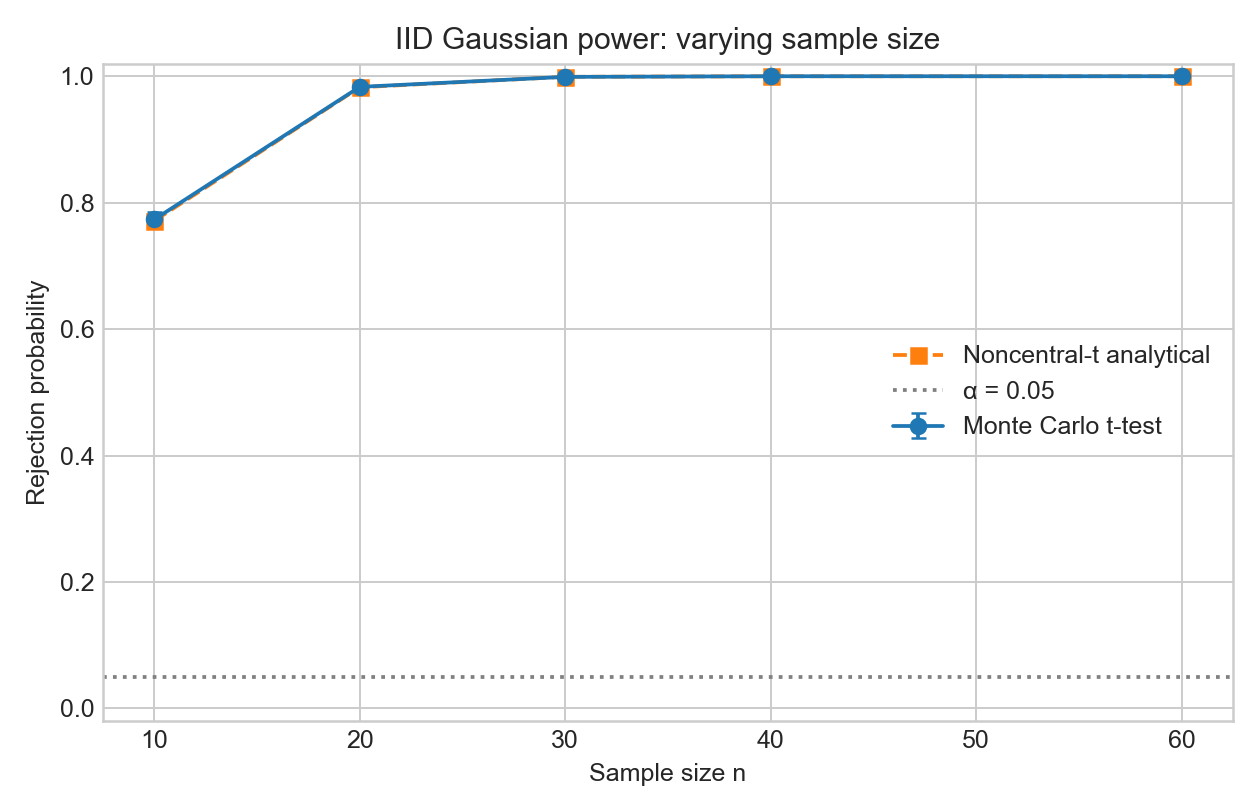

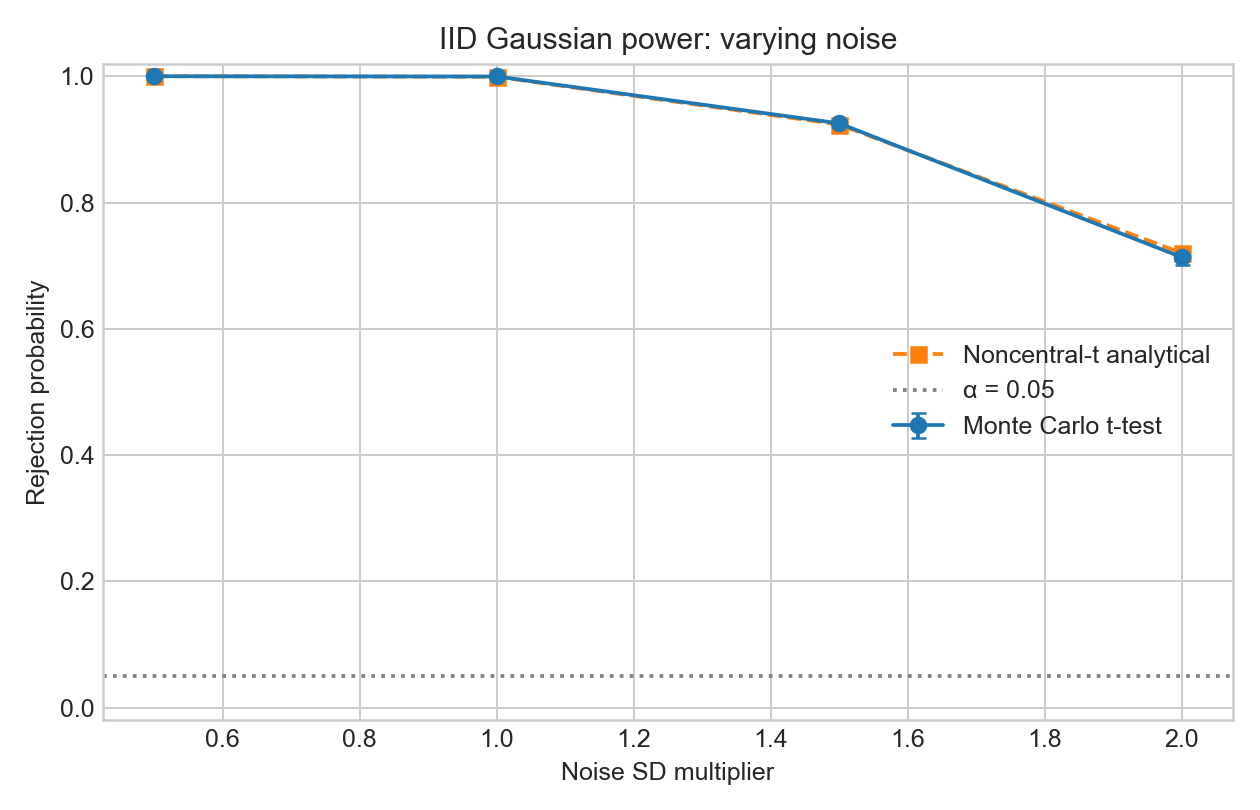

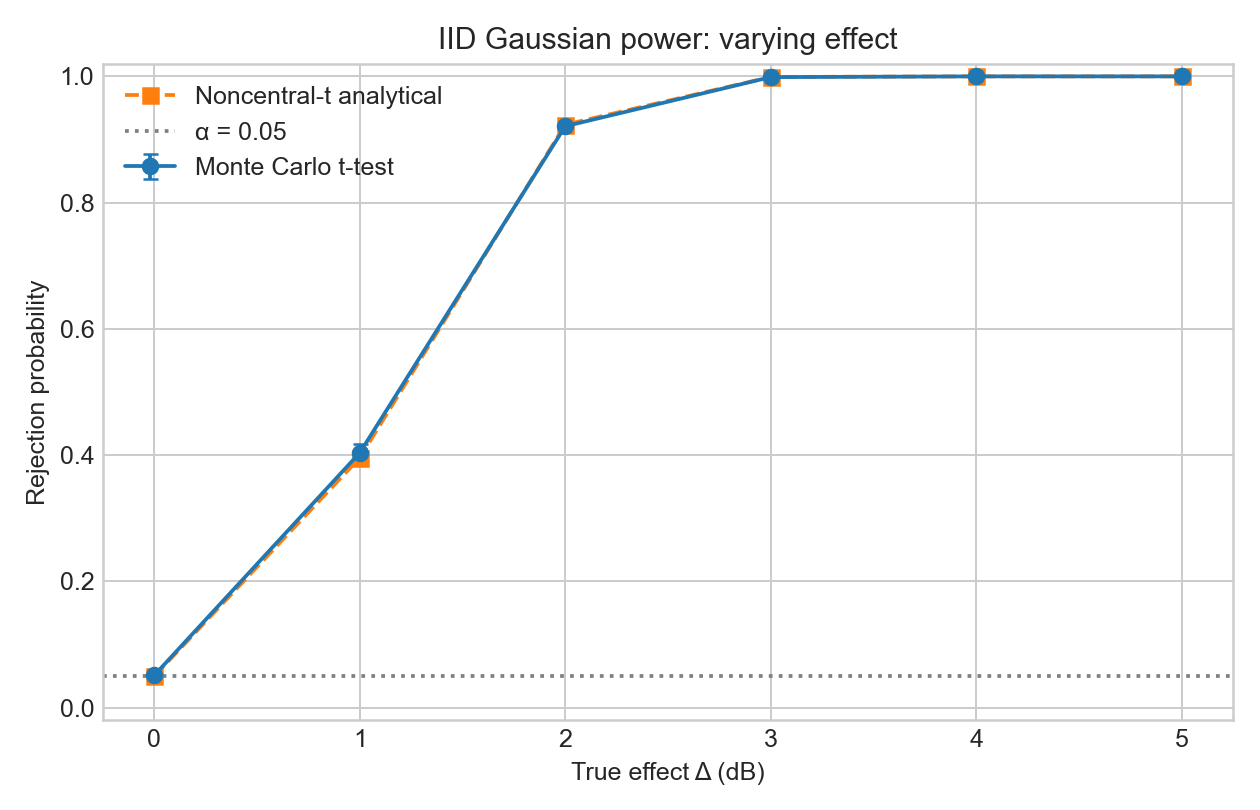

In [8]:
for figure in ("power_vs_sample_size.png", "power_vs_noise.png", "power_vs_effect.png"):
    display(Image(filename=str(ROOT / "results/figures" / figure)))


## 8. Temporal-dependence counterexample

Stationary Gaussian AR(1) series use known simulation `rho` values 0, 0.3, 0.6 and 0.9, stationary initialization, n=64, and effects 0 and 3 dB. The rho values are controlled truth in simulation. They are not inferred from the NOAA sample ACF. Compare Type I error, coverage, interval width and rejection under the alternative without presuming any method always performs best.

In [9]:
counterexample = pd.read_csv(ROOT / "results/raw/ar1_counterexample_summary.csv")
display(counterexample)
display(pd.read_json(ROOT / "results/raw/ar1_stationarity_checks.json"))


,rho,effect_db,method,replications,rejection_rate,rejection_ci_low,rejection_ci_high,coverage,coverage_ci_low,coverage_ci_high,mean_interval_width_db,median_interval_width_db
0,0.0,0.0,hac,2000,0.0560,0.046748,0.066954,0.9440,0.933046,0.953252,1.516219,1.506590
1,0.0,0.0,iid_t,2000,0.0425,0.034501,0.052253,0.9575,0.947747,0.965499,1.556741,1.555233
2,0.0,0.0,moving_block_bootstrap,2000,0.0690,0.058698,0.080954,0.9310,0.919046,0.941302,1.464279,1.453810
3,0.0,3.0,hac,2000,1.0000,0.998083,1.000000,0.9330,0.921192,0.943148,1.511974,1.502447
4,0.0,3.0,iid_t,2000,1.0000,0.998083,1.000000,0.9465,0.935754,0.955534,1.556124,1.557259
5,0.0,3.0,moving_block_bootstrap,2000,1.0000,0.998083,1.000000,0.9155,0.902500,0.926907,1.458991,1.446417
6,0.3,0.0,hac,2000,0.0930,0.081040,0.106520,0.9070,0.893480,0.918960,1.847168,1.837626
7,0.3,0.0,iid_t,2000,0.1580,0.142672,0.174639,0.8420,0.825361,0.857328,1.541239,1.535994
8,0.3,0.0,moving_block_bootstrap,2000,0.1085,0.095613,0.122889,0.8915,0.877111,0.904387,1.788859,1.777286
9,0.3,3.0,hac,2000,0.9995,0.997173,0.999912,0.9120,0.898781,0.923639,1.857514,1.841183


,rho,theoretical_mean,empirical_mean,theoretical_variance,empirical_variance,theoretical_lag1,empirical_lag1_mean,replications,series_length,seed
0,0.0,0,0.001322,9.754096,9.753452,0.0,-0.010639,30000,100,20262012
1,0.3,0,0.000590,9.754096,9.759948,0.3,0.280575,30000,100,20262013
2,0.6,0,0.000154,9.754096,9.758981,0.6,0.571488,30000,100,20262014
3,0.9,0,-0.006412,9.754096,9.760751,0.9,0.859991,30000,100,20262015


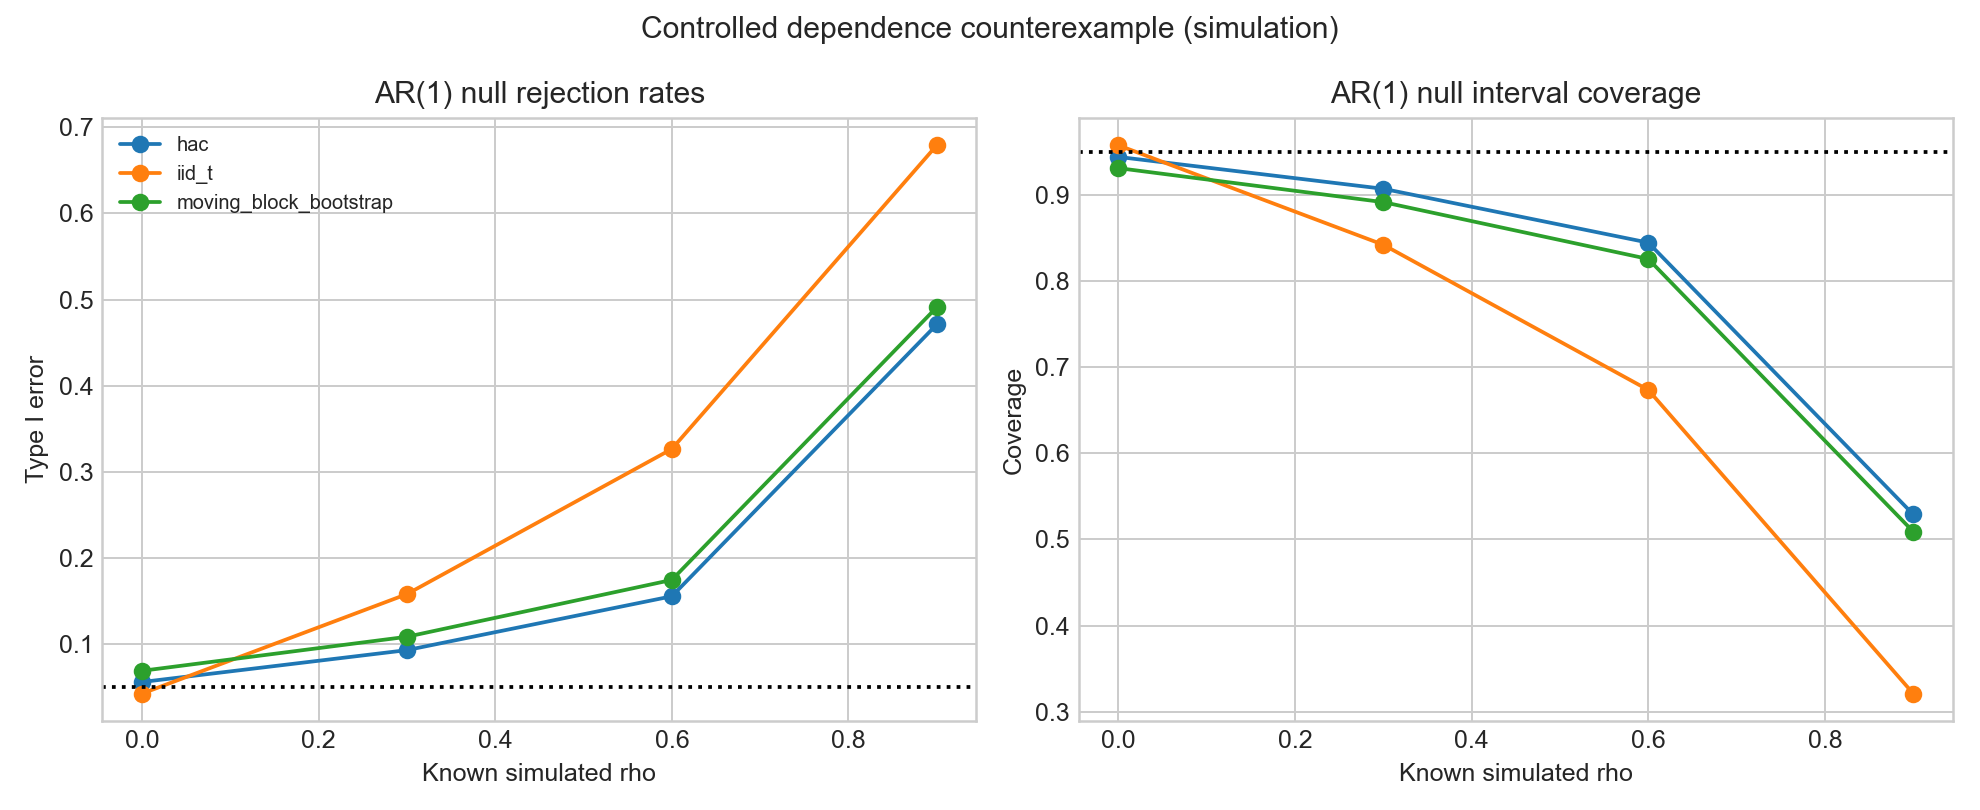

In [10]:
display(Image(filename=str(ROOT / "results/figures/counterexample_type1_coverage.png")))


## 9. Observed temporal dependence diagnostics

The daily ACF is exploratory and estimated from only 64 dates. The displayed approximate white-noise bands are descriptive reference bands, not universal coefficient-wise confidence intervals. No eligible-date gaps are bridged.

,lag_days,acf,n_pairs,approx_white_noise_bound
0,1,0.138379,63,0.245
1,2,0.109561,62,0.245
2,3,0.121037,61,0.245
3,7,0.002540,57,0.245
4,14,-0.034301,50,0.245


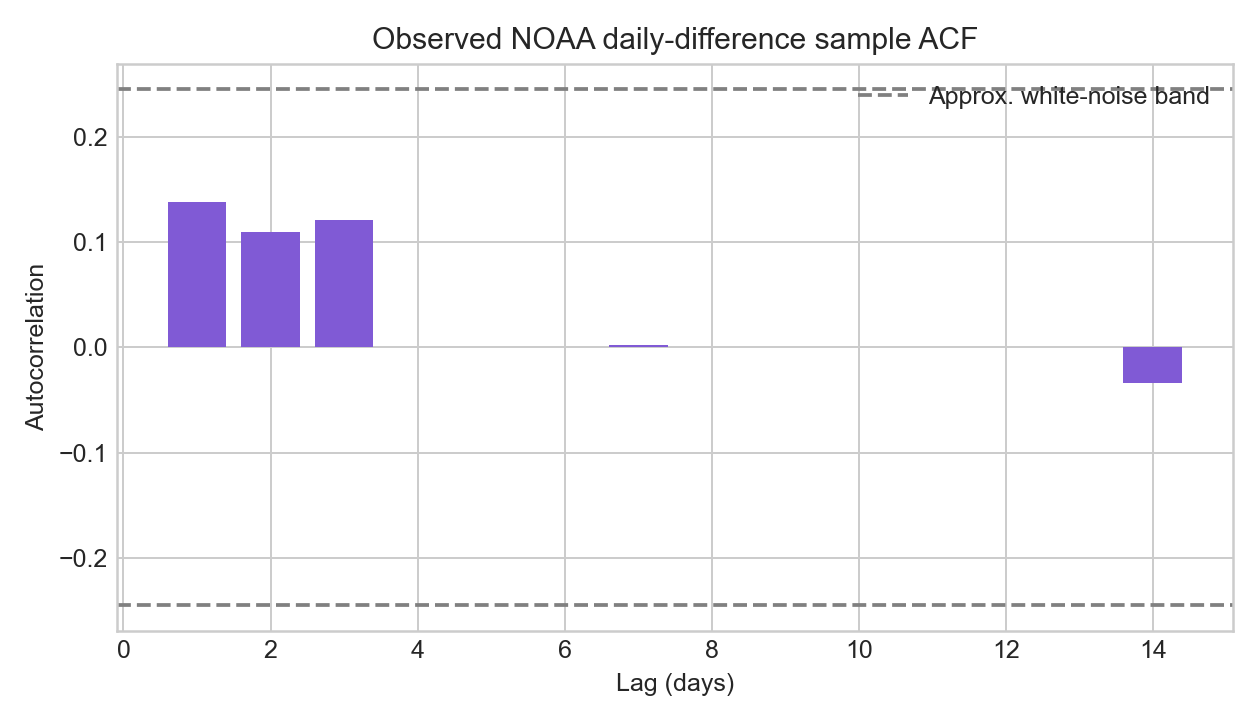

In [11]:
acf = pd.read_csv(ROOT / "results/raw/daily_difference_acf.csv")
display(acf)
display(Image(filename=str(ROOT / "results/figures/daily_difference_acf.png")))


## 10. Interpretation, limitations, and reproducibility

The real-data estimate describes this one deployment and the chosen published hourly indicator. The dataset's lower band edge remains conflicted (10 vs 20 Hz), and row-level QC is unavailable. Missingness, temporal dependence, possible nonstationarity, the brief deployment, and arithmetic averaging on the dB scale limit interpretation. Neither a p-value nor power simulation supplies causal evidence. Controlled simulations validate behavior under their stated data-generating processes only.

Reproduce in `nussem1` with `python src/run_phase1.py`, then execute this notebook from a clean kernel with `jupyter nbconvert --to notebook --execute notebook/DS_A2_inference_uncertainty.ipynb --output /tmp/DS_A2_executed.ipynb`. Run tests with `python -m unittest discover -s tests -v`. The resulting PDF, code, raw numerical outputs, source checksums, tests, protocol and AI-use log are versioned. Codex's automated checks are not independent student or reviewer verification. No course platform submission was made.
